<a href="https://colab.research.google.com/github/a20243018-del/CAVS/blob/main/TAREA_Thematics_MAP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TAREA Thematics MAP

In [ ]:
import geopandas as gpd
import pandas as pd
linkGit = 'https://raw.githubusercontent.com/a20243018-del/CAVS/main/'
linkworldMaps = 'worldMaps.gpkg'
someDataLink = 'some_dataworld.csv'

capas disponibles dentro del GeoPackage cargado desde GitHub

In [ ]:
gpd.list_layers(linkGit + linkWorldMaps)

,name,geometry_type
0,rivers,MultiLineString
1,cities,Point
2,countries,MultiPolygon


Recuperamos la capa de países

In [ ]:
countries = gpd.read_file(linkGit + linkworldMaps, layer='countries')
# see soe
countries

,COUNTRY,geometry
0,Aruba (Netherlands),"MULTIPOLYGON (((-69.88223 12.41111, -69.94695 ..."
1,Antigua and Barbuda,"MULTIPOLYGON (((-61.73889 17.54055, -61.75195 ..."
2,Afghanistan,"MULTIPOLYGON (((61.27656 35.60725, 61.29638 35..."
3,Algeria,"MULTIPOLYGON (((-5.15213 30.18047, -5.13917 30..."
4,Azerbaijan,"MULTIPOLYGON (((46.54037 38.87559, 46.49554 38..."
...,...,...
247,South Sudan,"MULTIPOLYGON (((34.21807 9.96458, 34.20722 9.9..."
248,Indonesia,"MULTIPOLYGON (((123.21846 -10.80917, 123.19832..."
249,East Timor,"MULTIPOLYGON (((124.41824 -9.3001, 124.40446 -..."
250,Curacao (Netherlands),"MULTIPOLYGON (((-68.96556 12.19889, -68.91196 ..."


In [ ]:
# Importamos la librería pandas para manipular tablas de datos
import pandas as pd

# Definimos el nombre de la variable para el archivo CSV
someDataLink = 'some_dataworld.csv'

# Cargamos los datos socioeconómicos desde tu repositorio de GitHub
someData = pd.read_csv(linkGit + someDataLink)

# Inspeccionamos la estructura del DataFrame, sus columnas y tipos de datos
someData.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 172 entries, 0 to 171
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Country       172 non-null    object 
 1   iso2          171 non-null    object 
 2   iso3          172 non-null    object 
 3   region        172 non-null    object 
 4   fragility     172 non-null    float64
 5   co2           172 non-null    int64  
 6   sq_km         172 non-null    int64  
 7   num_airports  172 non-null    int64  
 8   population    172 non-null    int64  
 9   mobiles       172 non-null    int64  
dtypes: float64(1), int64(5), object(4)
memory usage: 13.6+ KB


In [ ]:
someData.head()

,Country,iso2,iso3,region,fragility,co2,sq_km,num_airports,population,mobiles
0,AFGHANISTAN,AF,AFG,SOUTH ASIA,105.0,7893000,652230,68,40121552,23000000
1,ALBANIA,AL,ALB,EUROPE,58.9,3794000,28748,3,3107100,2610000
2,ALGERIA,DZ,DZA,AFRICA,75.4,151633000,2381740,95,47022473,51500000
3,ANGOLA,AO,AGO,AFRICA,87.8,19362000,1246700,107,37202061,25700000
4,ANTIGUA AND BARBUDA,AG,ATG,CENTRAL AMERICA AND THE CARIBBEAN,54.4,729000,443,4,102634,184000


Inspeccionamos

In [ ]:
countries.COUNTRY.head()

,COUNTRY
0,Aruba (Netherlands)
1,Antigua and Barbuda
2,Afghanistan
3,Algeria
4,Azerbaijan


inspeccionamos en el datafreme

In [ ]:
someData.Country.head()

,Country
0,AFGHANISTAN
1,ALBANIA
2,ALGERIA
3,ANGOLA
4,ANTIGUA AND BARBUDA


Existe diferencia entre los nombres de los países, debemos corregir .

In [ ]:
countries.rename(columns={'COUNTRY':'Country'},inplace=True)

pasamos todo a mayúsculas

In [ ]:
countries['Country']=countries.Country.str.upper()

In [ ]:
col_gdf = [col for col in countries.columns if col.upper() == 'COUNTRY'][0]
onlyDF = set(someData['Country']) - set(countries[col_gdf])
onlyDF

{'BAHAMAS (THE)',
 'BOLIVIA (PLURINATIONAL STATE OF)',
 'BRUNEI DARUSSALAM',
 'CABO VERDE',
 'CENTRAL AFRICAN REPUBLIC (THE)',
 'COMOROS (THE)',
 'CONGO (THE DEMOCRATIC REPUBLIC OF THE)',
 'CONGO (THE)',
 "CÔTE D'IVOIRE",
 'DOMINICAN REPUBLIC (THE)',
 'ESWATINI',
 'GAMBIA (THE)',
 'IRAN (ISLAMIC REPUBLIC OF)',
 'KOREA (THE REPUBLIC OF)',
 "LAO PEOPLE'S DEMOCRATIC REPUBLIC (THE)",
 'MICRONESIA (FEDERATED STATES OF)',
 'MOLDOVA (THE REPUBLIC OF)',
 'NETHERLANDS (THE)',
 'NIGER (THE)',
 'NORTH MACEDONIA',
 'NORTHERN MARIANA ISLANDS (THE)',
 'PHILIPPINES (THE)',
 'RUSSIAN FEDERATION (THE)',
 'SAMOA',
 'SUDAN (THE)',
 'TANZANIA, THE UNITED REPUBLIC OF',
 'TIMOR-LESTE',
 'UNITED ARAB EMIRATES (THE)',
 'UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN IRELAND (THE)',
 'UNITED STATES OF AMERICA (THE)'}

instalamos thefuzz para encontrar coicidencias

In [ ]:
!pip install thefuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 31.9 MB/s eta 0:00:00


guardamos los paises que no se encontraron coindicencias

In [ ]:
col_gdf = [col for col in countries.columns if col.upper() == 'COUNTRY'][0]
onlyGDF = set(countries[col_gdf]) - set(someData['Country'])

comprobamos similitud

In [ ]:
from thefuzz.process import extractOne as best
best('BAHAMAS (THE)',onlyGDF)

('BAHAMAS', 90)

Creamos la tabla con los puntajes de similitud ordenados

In [28]:
import pandas as pd


pd.DataFrame([(country, best(country, onlyGDF)[0], best(country, onlyGDF)[1]) for country in onlyDF]).sort_values(by=2)

,0,1,2
16,CÔTE D'IVOIRE,IVORY COAST,58
9,ESWATINI,MARTINIQUE (FRANCE),60
25,CABO VERDE,CAPE VERDE,80
21,TIMOR-LESTE,EAST TIMOR,81
2,LAO PEOPLE'S DEMOCRATIC REPUBLIC (THE),CZECH REPUBLIC,86
1,KOREA (THE REPUBLIC OF),NORTH KOREA,86
4,MOLDOVA (THE REPUBLIC OF),MOLDOVA,90
0,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,UNITED KINGDOM,90
7,NIGER (THE),NIGER,90
8,BOLIVIA (PLURINATIONAL STATE OF),BOLIVIA,90


Detectamos la columna de país y buscamos las coincidencias mencionadas

In [29]:
countries.Country[countries.Country.str.contains('SWAZ|LAO|SAMOA|KORE')]

,Country
9,AMERICAN SAMOA (US)
120,NORTH KOREA
122,SOUTH KOREA
126,LAOS
242,WESTERN SAMOA
243,SWAZILAND


realizamos cambios manuales

In [31]:
manualChanges = {
    'SWAZILAND': 'ESWATINI',
    'LAOS': "LAO PEOPLE'S DEMOCRATIC REPUBLIC (THE)",
    'WESTERN SAMOA': 'SAMOA'
}

detectamos la columna de cada país de forma segura

In [32]:
col_gdf = [col for col in countries.columns if col.upper() == 'COUNTRY'][0]

calculamos las diferencias

In [33]:
onlyDF = set(someData['Country']) - set(countries[col_gdf])
onlyGDF = set(countries[col_gdf]) - set(someData[col_gdf] if col_gdf in someData else someData['Country'])

volvemos a ejecutar...

In [34]:
pd.DataFrame([(country, best(country,onlyGDF)[0],best(country,onlyGDF)[1]) for country in onlyDF]).sort_values(2)

,0,1,2
16,CÔTE D'IVOIRE,IVORY COAST,58
9,ESWATINI,MARTINIQUE (FRANCE),60
25,CABO VERDE,CAPE VERDE,80
21,TIMOR-LESTE,EAST TIMOR,81
2,LAO PEOPLE'S DEMOCRATIC REPUBLIC (THE),CZECH REPUBLIC,86
1,KOREA (THE REPUBLIC OF),NORTH KOREA,86
4,MOLDOVA (THE REPUBLIC OF),MOLDOVA,90
0,UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN I...,UNITED KINGDOM,90
7,NIGER (THE),NIGER,90
8,BOLIVIA (PLURINATIONAL STATE OF),BOLIVIA,90


realizamos los cambios

In [35]:
changesToDF={country: best(country,onlyGDF)[0] for country in onlyDF}
changesToDF

{'UNITED KINGDOM OF GREAT BRITAIN AND NORTHERN IRELAND (THE)': 'UNITED KINGDOM',
 'KOREA (THE REPUBLIC OF)': 'NORTH KOREA',
 "LAO PEOPLE'S DEMOCRATIC REPUBLIC (THE)": 'CZECH REPUBLIC',
 'SUDAN (THE)': 'SUDAN',
 'MOLDOVA (THE REPUBLIC OF)': 'MOLDOVA',
 'TANZANIA, THE UNITED REPUBLIC OF': 'TANZANIA',
 'GAMBIA (THE)': 'GAMBIA',
 'NIGER (THE)': 'NIGER',
 'BOLIVIA (PLURINATIONAL STATE OF)': 'BOLIVIA',
 'ESWATINI': 'MARTINIQUE (FRANCE)',
 'COMOROS (THE)': 'COMOROS',
 'CONGO (THE)': 'CONGO',
 'CONGO (THE DEMOCRATIC REPUBLIC OF THE)': 'DEMOCRATIC REPUBLIC OF THE CONGO',
 'NETHERLANDS (THE)': 'NETHERLANDS',
 'CENTRAL AFRICAN REPUBLIC (THE)': 'CENTRAL AFRICAN REPUBLIC',
 'RUSSIAN FEDERATION (THE)': 'RUSSIA',
 "CÔTE D'IVOIRE": 'IVORY COAST',
 'IRAN (ISLAMIC REPUBLIC OF)': 'IRAN',
 'NORTH MACEDONIA': 'MACEDONIA',
 'DOMINICAN REPUBLIC (THE)': 'DOMINICAN REPUBLIC',
 'UNITED STATES OF AMERICA (THE)': 'UNITED STATES',
 'TIMOR-LESTE': 'EAST TIMOR',
 'SAMOA': 'AMERICAN SAMOA (US)',
 'UNITED ARAB EMIRATE

In [36]:
someData.replace(to_replace={'Country':changesToDF},inplace=True)

para emparejar

In [37]:
onlyDF=set(someData.Country)- set(countries.Country)
onlyGDF=set(countries.Country)- set(someData.Country)
[(country, best(country,onlyGDF)) for country in onlyDF]

[]

In [38]:
theMapAndData=countries.merge(someData, on='Country')

In [39]:
theMapAndData.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 172 entries, 0 to 171
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   Country       172 non-null    object  
 1   geometry      172 non-null    geometry
 2   iso2          171 non-null    object  
 3   iso3          172 non-null    object  
 4   region        172 non-null    object  
 5   fragility     172 non-null    float64 
 6   co2           172 non-null    int64   
 7   sq_km         172 non-null    int64   
 8   num_airports  172 non-null    int64   
 9   population    172 non-null    int64   
 10  mobiles       172 non-null    int64   
dtypes: float64(1), geometry(1), int64(5), object(4)
memory usage: 14.9+ KB


In [40]:
theMapAndData.to_file("worldindicators.json")

# Thematics: the DDM (Dot Density Map)

solo regiones solicitadas

In [41]:
regiones_target = [
    'NORTH AMERICA',
    'SOUTH AMERICA',
    'CENTRAL AMERICA',
    'CARIBBEAN',
    'CENTRAL AMERICA AND THE CARIBBEAN',
    'NORTHERN AMERICA'
]

<Axes: >

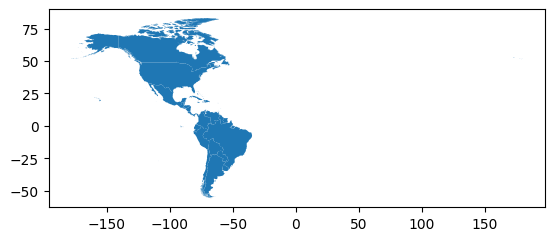

In [44]:
america = theMapAndData[theMapAndData['region'].str.upper().isin(regiones_target)].dropna(subset=['mobiles']).copy()
america.plot()

Preprocesamiento: agregación

Definimos el DataFrame para puntos y asignamos el valor de cada punto

In [45]:
justDots = america.copy()

con proporción de 1/150 en el mapa

In [60]:
dot_value = america['mobiles'].max() / 150
print(f"Cada punto representa aproximadamente {int(dot_value):,} teléfonos móviles.")

Cada punto representa aproximadamente 2,573,333 teléfonos móviles.


In [63]:
justDots = america.copy()
justDots['num_dots'] = (justDots['mobiles'] / dot_value).astype(int)

generamos ubicaciones aleatorias

In [48]:
justDots = justDots.sample_points(size=justDots['num_dots']).explode(index_parts=True)

visualisamos

In [62]:
justDots

,sampled_points
0,POINT (-62.7499 -27.79288)
1,POINT (-70.36379 -48.66725)
2,POINT (-71.48552 -47.01206)
3,POINT (-66.44415 -54.70419)
4,POINT (-69.01732 -40.87625)
...,...
430,POINT (-65.12188 8.46804)
431,POINT (-61.26956 4.50628)
432,POINT (-69.08609 11.15175)
433,POINT (-66.83094 8.08583)


In [50]:
type(justDots)

geopandas.geoseries.GeoSeries

Preprocesamiento: construcción de GDF a partir de GS

In [51]:
justDots.reset_index(drop=True, inplace=True)
america_dots=gpd.GeoDataFrame(geometry=justDots)
america_dots

,geometry
0,POINT (-62.7499 -27.79288)
1,POINT (-70.36379 -48.66725)
2,POINT (-71.48552 -47.01206)
3,POINT (-66.44415 -54.70419)
4,POINT (-69.01732 -40.87625)
...,...
430,POINT (-65.12188 8.46804)
431,POINT (-61.26956 4.50628)
432,POINT (-69.08609 11.15175)
433,POINT (-66.83094 8.08583)


ahora tenemos un GS

In [52]:
america_dots.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 435 entries, 0 to 434
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   geometry  435 non-null    geometry
dtypes: geometry(1)
memory usage: 3.5 KB


cambiando la proporción

<Axes: >

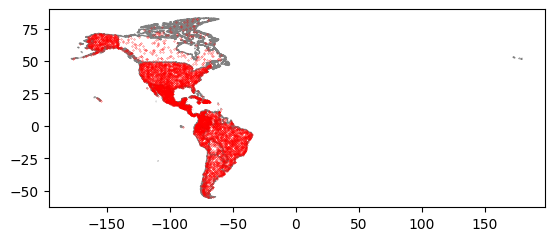

In [69]:
base=america.plot(facecolor="white",#color of polygon fill
               edgecolor='grey') #color of border
america_dots.plot(markersize=0.05, color='red',ax=base)

<Axes: >

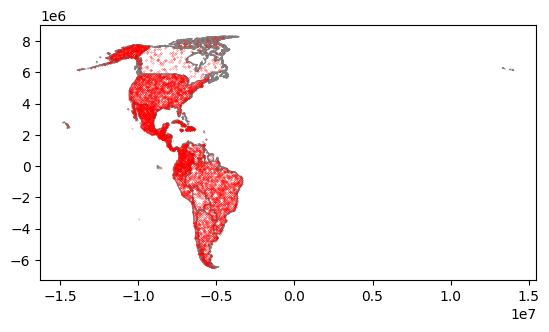

In [70]:
base=america.to_crs(8857).plot(facecolor="white",
                              edgecolor='grey')
america_dots.to_crs(8857).plot(markersize=0.05, color='red',ax=base)

In [72]:
america_8857=america.to_crs(8857)
america_dots_8857=america_dots.to_crs(8857)

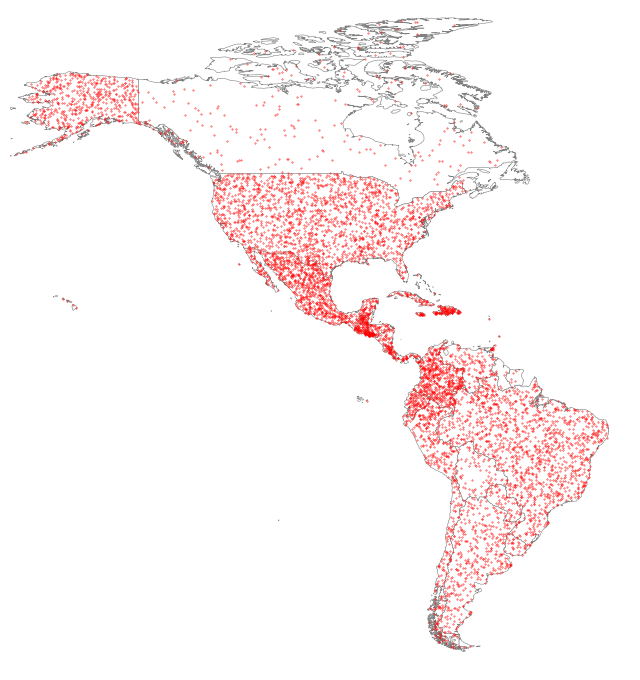

In [73]:
import matplotlib.pyplot as plt

#Crear la figura
fig, base = plt.subplots(figsize=(8, 10))

#Graficar la capa base y los puntos
america.plot(ax=base, facecolor="white", edgecolor="grey", linewidth=0.4)
america_dots.plot(ax=base, markersize=0.10, color="red")

#Eliminar ejes y ajustar encuadre exactamente como el profesor
base.axis("off")
base.set_xlim(-170, -30)
base.set_ylim(-60, 85)

plt.show()

# Thematics: the PSM (Proportional Symbol Map)

Ubicación de un símbolo, generalmente el centroide del polígono.

In [75]:
america_8857_centroids = america_8857.copy()

# Africa_8857_centroids will have a new geometry:
america_8857_centroids['geometry'] = america_8857_centroids['geometry'].centroid

Un tamaño con valores variables (no constante como en los DDM). Volvamos a usar de moviles.

In [76]:
america_8857_centroids['size'] = america_8857_centroids['mobiles'].apply(lambda x: x**0.5/100)

para la gráfica

<Axes: >

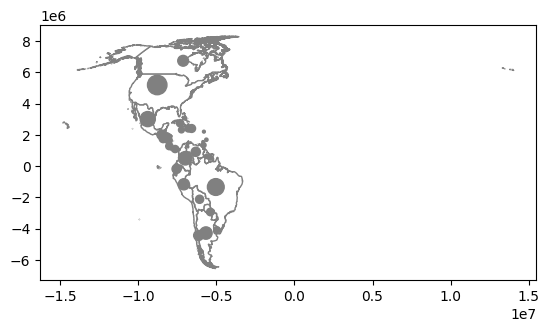

In [78]:
base=america_8857.plot(facecolor="white",
                      edgecolor='grey')
# Plot the centroids on top
america_8857_centroids.plot(
    ax=base,
    markersize=america_8857_centroids['size'],
    color='grey'
)

trazamos gráfica de CANADA

In [82]:
base = america_8857[america_8857.Country == "CANADA"].explore(tiles="CartoDB positron")
america_8857_centroids[america_8857_centroids.Country == "CANADA"].explore(
    m=base,
    color="red",
    tiles="CartoDB positron"
)

Preprocesamiento: Cálculo de nuevas columnas

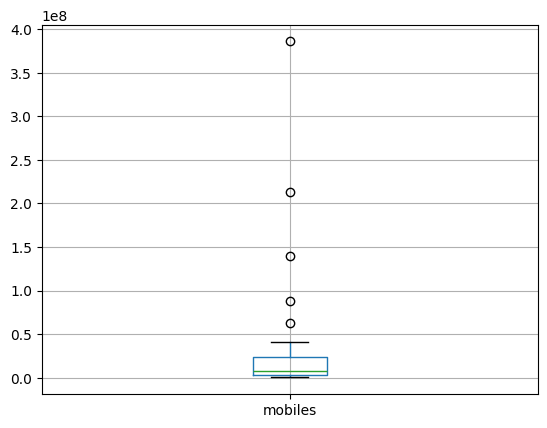

In [83]:
boxplotInfo=america_8857_centroids.boxplot(column='mobiles',return_type="dict")

podemos ver que hay valores atípicos


ahora vamos a extraer esso valores atípicos  filtrar los centroides que contienen esos valores atípicos

In [85]:
import matplotlib.pyplot as plt


box_res = plt.boxplot(america_8857_centroids['mobiles'])
plt.close()

outliers = box_res['fliers'][0].get_ydata()


america_8857_centroids[america_8857_centroids.mobiles.isin(outliers)]

,Country,geometry,iso2,iso3,region,fragility,co2,sq_km,num_airports,population,mobiles,size
8,ARGENTINA,POINT (-5662635.537 -4288178.971),AR,ARG,SOUTH AMERICA,46.0,193205000,2780400,764,46994384,62700000,79.183332
23,BRAZIL,POINT (-5031270.911 -1340905.017),BR,BRA,SOUTH AMERICA,71.8,456670000,8515770,5297,220051512,213000000,145.945195
38,COLOMBIA,POINT (-6986996.354 498813.099),CO,COL,SOUTH AMERICA,75.7,81007000,1138910,661,49588357,87400000,93.487967
110,MEXICO,POINT (-9387058.358 3007442.824),MX,MEX,NORTH AMERICA,69.7,463739000,1964375,1580,130739927,140000000,118.321596
159,UNITED STATES,POINT (-8781753.271 5190532.313),US,USA,NORTH AMERICA,38.0,5144361000,9833517,16116,341963408,386000000,196.468827


 podemos crear una columna como indicador de valores atípicos:

In [86]:
america_8857_centroids['mobiles_outlier']=america_8857_centroids.mobiles.isin(outliers)*1

## see
america_8857_centroids

,Country,geometry,iso2,iso3,region,fragility,co2,sq_km,num_airports,population,mobiles,size,mobiles_outlier
0,ANTIGUA AND BARBUDA,POINT (-5792572.262 2203213.245),AG,ATG,CENTRAL AMERICA AND THE CARIBBEAN,54.4,729000,443,4,102634,184000,4.289522,0
8,ARGENTINA,POINT (-5662635.537 -4288178.971),AR,ARG,SOUTH AMERICA,46.0,193205000,2780400,764,46994384,62700000,79.183332,1
12,BARBADOS,POINT (-5634709.905 1685798.228),BB,BRB,CENTRAL AMERICA AND THE CARIBBEAN,48.0,1703000,430,1,304139,323000,5.683309,0
15,BAHAMAS,POINT (-7022207.32 3059294.94),BS,BHS,CENTRAL AMERICA AND THE CARIBBEAN,48.8,3984000,13880,54,410862,400000,6.324555,0
17,BELIZE,POINT (-8315016.05 2195039.229),BZ,BLZ,CENTRAL AMERICA AND THE CARIBBEAN,62.5,541000,22966,27,415789,264000,5.138093,0
19,BOLIVIA,POINT (-6068711.373 -2125321.301),BO,BOL,SOUTH AMERICA,72.9,17786000,1098581,201,12311974,12000000,34.641016,0
23,BRAZIL,POINT (-5031270.911 -1340905.017),BR,BRA,SOUTH AMERICA,71.8,456670000,8515770,5297,220051512,213000000,145.945195,1
28,CANADA,POINT (-7122154.163 6740136.604),CA,CAN,NORTH AMERICA,20.0,612084000,9984670,1459,38794813,36500000,60.415230,0
35,CHILE,POINT (-6129887.491 -4440461.25),CL,CHL,SOUTH AMERICA,38.9,88333000,756102,379,18664652,26700000,51.672043,0
38,COLOMBIA,POINT (-6986996.354 498813.099),CO,COL,SOUTH AMERICA,75.7,81007000,1138910,661,49588357,87400000,93.487967,1


esa informaión podemos usarla en

<Axes: >

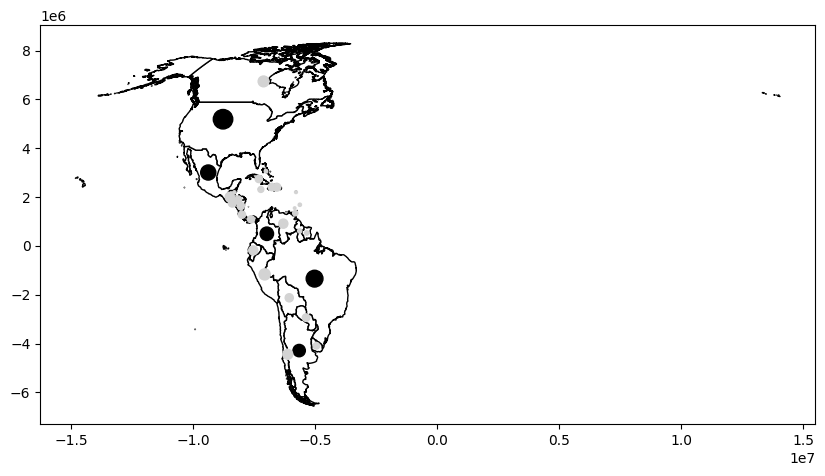

In [87]:
base = america_8857.plot(color='white', edgecolor='black', figsize=(10,10))

# Define your color map
mapcolor = {1: 'black', 0: 'lightgrey'}

# Plot the centroids on top
america_8857_centroids.plot(
    ax=base,
    markersize=america_8857_centroids['size'],
    color=america_8857_centroids['mobiles_outlier'].map(mapcolor)
)

se puede notar los valores atípicos, pero podemos hcaer crear dos mapas de centroides

In [90]:
# Create explicit copies of the DataFrames
maerica_8857_centroids_out = america_8857_centroids[america_8857_centroids.mobiles_outlier==1].copy()
america_8857_centroids_no_out = america_8857_centroids[america_8857_centroids.mobiles_outlier==0].copy()


calculamos los tamaños de cada uno

1. Separar los centroides en dos grupos: atípicos (out) y no atípicos (no_out)
2. Recalcular el tamaño del símbolo para cada grupo

In [92]:

america_8857_centroids_out = america_8857_centroids[america_8857_centroids.mobiles.isin(outliers)].copy()
america_8857_centroids_no_out = america_8857_centroids[~america_8857_centroids.mobiles.isin(outliers)].copy()

america_8857_centroids_out['size'] = america_8857_centroids_out['mobiles'].apply(lambda x: x**0.5 / 50)
america_8857_centroids_no_out['size'] = america_8857_centroids_no_out['mobiles'].apply(lambda x: x**0.5 / 50)

(np.float64(-16271317.330745108),
 np.float64(15480699.862044137),
 np.float64(-7300598.825011038),
 np.float64(9046041.27592503))

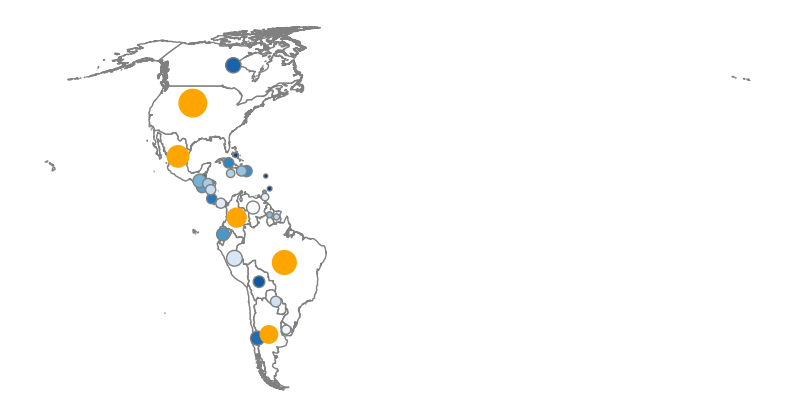

In [93]:
base = america_8857.plot(color='white', edgecolor='grey', figsize=(10, 10))

america_8857_centroids_no_out.plot(
    ax=base,
    markersize=america_8857_centroids_no_out['size'],
    edgecolor='grey',
    c=america_8857_centroids_no_out['size'],
    cmap='Blues_r'
)

america_8857_centroids_out.plot(
    ax=base,
    markersize=america_8857_centroids_out['size'],
    color='orange'
)

#  para limpiar los bodes del mpa
base.axis('off')

# Thematics: Choropleths

no es lo qeu se busca

<Axes: >

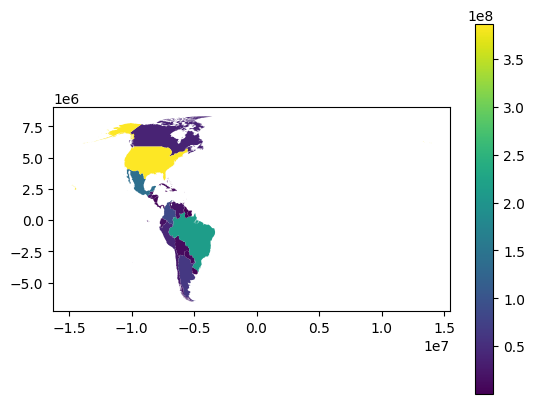

In [96]:
america_8857.plot(column='mobiles', legend=True)

este es el mapa qu se busca graficar

<Axes: >

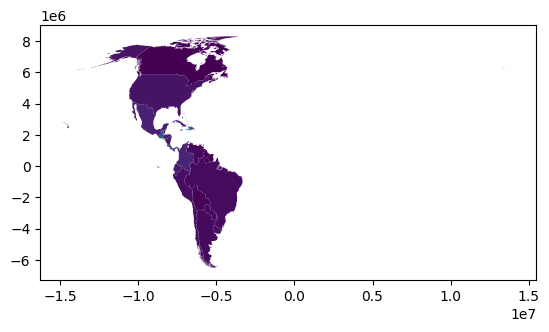

In [97]:
america_8857.plot(america_8857.mobiles/america_8857.sq_km)

In [98]:
## do you have these installed?
# ! pip show numba mapclassify numpy

In [99]:
america_8857['mobiles_density']=america_8857.mobiles/america_8857.sq_km

In [100]:
import mapclassify
import numpy as np

np.random.seed(12345)

K = 5
theVar = america_8857['mobiles']

ei5 = mapclassify.EqualInterval(theVar, k=K)

msd = mapclassify.StdMean(theVar)

q5 = mapclassify.Quantiles(theVar, k=K)

mb5 = mapclassify.MaximumBreaks(theVar, k=K)
ht = mapclassify.HeadTailBreaks(theVar)

fj5 = mapclassify.FisherJenks(theVar, k=K)
jc5 = mapclassify.JenksCaspall(theVar, k=K)
mp5 = mapclassify.MaxP(theVar, k=K)

recopilar la métrica de ADCM, convertir en dataFrame y asignicar nombres, mostrar resultado ordenado.  

In [101]:
import numpy as np
import pandas as pd

class5 = [ei5, msd, q5, mb5, ht, fj5, jc5, mp5]

fits = np.array([c.adcm for c in class5])

adcms = pd.DataFrame(fits)
adcms['classifier'] = [c.name for c in class5]
adcms.columns = ['ADCM', 'Classifier']

adcms.sort_values(by='ADCM')

,ADCM,Classifier
5,202102000.0,FisherJenks
3,248222000.0,MaximumBreaks
4,282382000.0,HeadTailBreaks
0,300822000.0,EqualInterval
6,384762000.0,JenksCaspall
7,392412000.0,MaxP
1,501182000.0,StdMean
2,603055000.0,Quantiles


<Axes: ylabel='Classifier'>

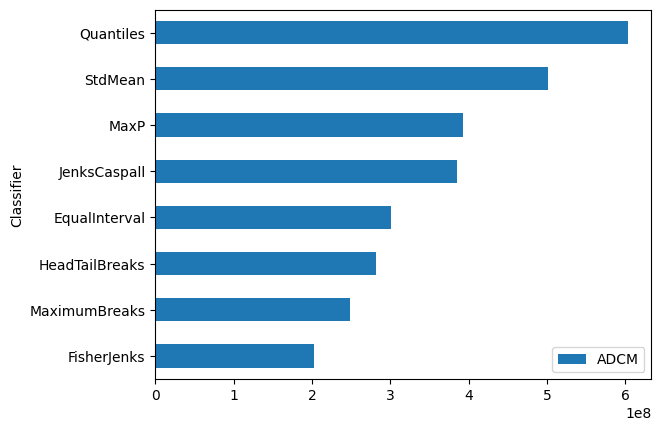

In [102]:
adcms.sort_values('ADCM').plot.barh(x='Classifier')

In [105]:
america_8857['mobiles_density_FJ5'] = fj5.yb
america_8857[['mobiles_density','mobiles_density_FJ5']].head(20)

,mobiles_density,mobiles_density_FJ5
0,415.349887,0
8,22.550712,1
12,751.162791,0
15,28.818444,0
17,11.495254,0
19,10.923182,0
23,25.012418,3
28,3.655604,1
35,35.312696,0
38,76.740041,1


In [107]:
# renaming
newLabelsForLevels={0:"0_VeryLow", 1:"1_Low", 2:"2_Middle", 3:"3_High", 4:"4_VeryHigh"}

america_8857['mobiles_density_FJ5_cat']=america_8857.loc[:,'mobiles_density_FJ5'].replace(newLabelsForLevels)

# we have
america_8857[['mobiles_density','mobiles_density_FJ5','mobiles_density_FJ5_cat']].head(20)

,mobiles_density,mobiles_density_FJ5,mobiles_density_FJ5_cat
0,415.349887,0,0_VeryLow
8,22.550712,1,1_Low
12,751.162791,0,0_VeryLow
15,28.818444,0,0_VeryLow
17,11.495254,0,0_VeryLow
19,10.923182,0,0_VeryLow
23,25.012418,3,3_High
28,3.655604,1,1_Low
35,35.312696,0,0_VeryLow
38,76.740041,1,1_Low


podemos generar un mapa coroplético discreto

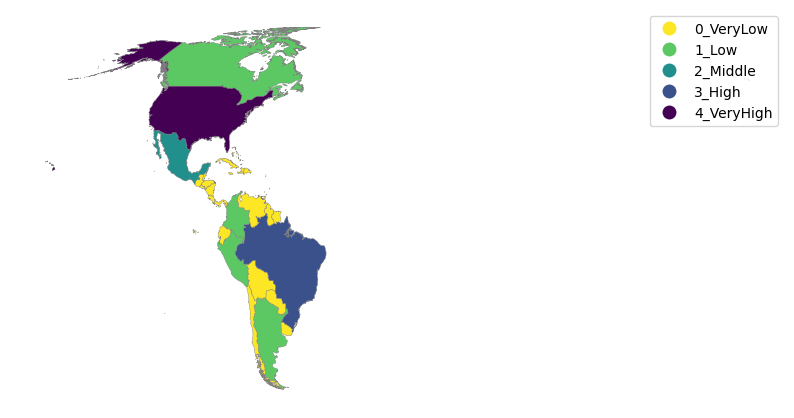

In [108]:
import matplotlib.pyplot as plt

f, ax = plt.subplots(1, figsize=(10, 10))
america_8857.plot(column='mobiles_density_FJ5_cat', # variable to plot
                 cmap='viridis_r', # set of colors
                 categorical=True, # can be interpreted as category
                 edgecolor='grey', # border color
                 linewidth=0.3, # width of border
                 legend=True, # need a legend?
                 ax=ax
       )

ax.set_axis_off()